# Лабораторная работа № 2
## Машинное обучение на больших данных с использованием фреймворка Apache Spark и библиотеки SparkML
### Часть 2. Бинарная классификация: логистическая регрессия (`LogisticRegression`)

**Задача:** по условиям ДТП — место, время, тип дороги, погода, объекты рядом — предсказать, будет ли оно тяжёлым, то есть надолго затруднит движение (тяжесть 3 или 4). Такая оценка в момент сообщения о ДТП помогает решить, куда направлять службы в первую очередь.

**Вход:** таблица `sobd_accidents.us_accidents_clean` из лабораторной № 1 (вариант 2: классификация — `LogisticRegression`).

### Оглавление

1. [Подготовка](#ch1)
2. [Постановка задачи](#ch2)
3. [Данные и целевой признак](#ch3)
4. [Разделение по времени](#ch4)
5. [Выборка для следующей работы](#ch5)
6. [Конвейер признаков и модели](#ch6)
7. [Подбор гиперпараметров](#ch7)
8. [Качество на тесте](#ch8)
9. [ROC- и PR-кривые](#ch9)
10. [Порог решения](#ch10)
11. [Интерпретация коэффициентов](#ch11)
12. [Сохранение модели](#ch12)
13. [Выводы](#ch13)

<a id="ch1"></a>
## 1. Подготовка

**Путь:** подключаем библиотеки, запускаем сессию и открываем очищенную таблицу.

In [1]:
import os

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from pyspark.ml import Pipeline, PipelineModel
from pyspark.ml.classification import LogisticRegression
from pyspark.ml.evaluation import BinaryClassificationEvaluator
from pyspark.ml.feature import OneHotEncoder, StandardScaler, StringIndexer, VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.tuning import CrossValidator, ParamGridBuilder
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

user = os.getenv("USER")

spark = (
    SparkSession.builder
    .appName("lab2-part2-logistic-regression")
    .master("yarn")
    .config("spark.executor.instances", "2")
    .config("spark.executor.cores", "2")
    .config("spark.executor.memory", "1536m")
    .config("spark.sql.shuffle.partitions", "16")  # 16 разделов на 4 ядра вместо 200
    .config("spark.sql.extensions", "org.apache.iceberg.spark.extensions.IcebergSparkSessionExtensions")
    .config("spark.sql.catalog.spark_catalog", "org.apache.iceberg.spark.SparkCatalog")
    .config("spark.sql.catalog.spark_catalog.type", "hadoop")
    .config("spark.sql.catalog.spark_catalog.warehouse", f"hdfs:///user/{user}/warehouse")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
spark.catalog.setCurrentDatabase("sobd_accidents")

sns.set_theme(style="whitegrid")
FIGURES = "/workspace/figures"


def save(name):
    """Сохраняет текущий рисунок для главы курсовой."""
    plt.savefig(f"{FIGURES}/{name}.png", dpi=150, bbox_inches="tight")

Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/20 05:27:04 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable


In [2]:
clean = spark.table("us_accidents_clean")
print(f"ДТП в очищенной таблице: {clean.count():,}")

ДТП в очищенной таблице: 7,538,337


<a id="ch2"></a>
## 2. Постановка задачи

**Целевой признак** `severe` = 1, если тяжесть 3 или 4.

**Данные:** только `Source2`. Разведочный анализ (лаб. № 1, глава 11) показал, что источники размечают тяжесть по-разному, а у `Source1` шкала менялась по годам. У `Source2` доля тяжёлых стабильна — на нём модель учит одну и ту же величину.

**Признаки** — только то, что известно в момент сообщения о ДТП:

| Группа | Признаки | Кодирование |
| --- | --- | --- |
| Категориальные | `state`, `road_type`, `weather_group`, `sunrise_sunset` | индекс + one-hot |
| Календарные | `hour`, `weekday`, `month` | one-hot: зависимость от часа нелинейная |
| Количественные | `temperature_f`, `humidity_pct`, `pressure_in`, `visibility_mi`, `wind_speed_mph` | стандартизация |
| Бинарные | 12 признаков «объект рядом» | как есть (0/1) |

**Не используем:** `distance_mi` и `duration_min` — известны только после ДТП (утечка ответа); `year` — тестируем на будущих годах; `city`, `county` — тысячи значений, место уже задаёт штат.

**Метрики:** `AUC-ROC` и `AUC-PR`, а при выбранном пороге — точность (precision) и полнота (recall).

<a id="ch3"></a>
## 3. Данные и целевой признак

**Путь:** берём `Source2`, строим `severe` → проверяем баланс классов и его стабильность по годам.

In [3]:
data = (
    clean.filter(F.col("source") == "Source2")
    .withColumn("severe", (F.col("severity") >= 3).cast("int"))
)

(data.groupBy("year")
     .agg(F.count("*").alias("records"), F.avg("severe").alias("severe_share"))
     .orderBy("year")
     .toPandas().round(3))

,year,records,severe_share
0,2016,279568,0.368
1,2017,538972,0.364
2,2018,712885,0.360
3,2019,671419,0.303
4,2020,447447,0.307
5,2021,430678,0.343
6,2022,215964,0.343


Доля тяжёлых держится около трети во все годы — классы умеренно несбалансированы, специальная балансировка не нужна.

<a id="ch4"></a>
## 4. Разделение по времени

**Путь:** модель будет оценивать новые ДТП, поэтому учим её на 2016–2020 годах, а проверяем на 2021–2022.

In [4]:
train = data.filter(F.col("year") <= 2020)
test = data.filter(F.col("year") >= 2021)

for name, part in [("Обучение", train), ("Тест", test)]:
    row = part.agg(F.count("*").alias("n"), F.avg("severe").alias("share")).first()
    print(f"{name}: {row['n']:,} записей, доля тяжёлых {row['share']:.1%}")

Обучение: 2,650,291 записей, доля тяжёлых 33.8%


Тест: 646,642 записей, доля тяжёлых 34.3%


<a id="ch5"></a>
## 5. Выборка для следующей работы

**Путь:** отделяем от теста около 1000 записей и сохраняем в `streaming-data.csv` — в лабораторной № 3 они будут поступать в модель потоком. В оценке качества эти записи не участвуют.

In [5]:
fraction = 1000 / test.count()
stream, test = test.randomSplit([fraction, 1 - fraction], seed=42)

stream.toPandas().to_csv("streaming-data.csv", index=False)
print(f"В streaming-data.csv записано {stream.count()} записей")

В streaming-data.csv записано 988 записей


In [6]:
train = train.cache()
test = test.cache()
print(f"Обучение: {train.count():,}, тест: {test.count():,}")

Обучение: 2,650,291, тест: 645,654


<a id="ch6"></a>
## 6. Конвейер признаков и модели

**Путь:** собираем конвейер, который сам кодирует признаки и обучает модель:

1. `StringIndexer` — строки категорий → номера;
2. `OneHotEncoder` — номера категорий и календарь → векторы 0/1;
3. `VectorAssembler` + `StandardScaler` — количественные признаки → вектор с нулевым средним и единичным разбросом, чтобы коэффициенты были сравнимы;
4. `VectorAssembler` — всё в один вектор `features`;
5. `LogisticRegression`.

In [7]:
categorical = ["state", "road_type", "weather_group", "sunrise_sunset"]
calendar = ["hour", "weekday", "month"]
numeric = ["temperature_f", "humidity_pct", "pressure_in", "visibility_mi", "wind_speed_mph"]
poi = ["amenity", "bump", "crossing", "give_way", "junction", "no_exit",
       "railway", "roundabout", "station", "stop", "traffic_calming", "traffic_signal"]

indexed = [f"{c}_index" for c in categorical]
onehot = [f"{c}_onehot" for c in categorical + calendar]

indexer = StringIndexer(inputCols=categorical, outputCols=indexed, handleInvalid="keep")
encoder = OneHotEncoder(inputCols=indexed + calendar, outputCols=onehot, handleInvalid="keep")
numeric_assembler = VectorAssembler(inputCols=numeric, outputCol="numeric")
scaler = StandardScaler(inputCol="numeric", outputCol="numeric_scaled", withMean=True)
assembler = VectorAssembler(inputCols=onehot + ["numeric_scaled"] + poi, outputCol="features")
logreg = LogisticRegression(featuresCol="features", labelCol="severe", maxIter=50)

pipeline = Pipeline(stages=[indexer, encoder, numeric_assembler, scaler, assembler, logreg])

<a id="ch7"></a>
## 7. Подбор гиперпараметров

**Путь:** перебираем силу регуляризации `regParam` и её вид `elasticNetParam` (0 — L2, 1 — L1) кросс-валидацией на трёх блоках, критерий — `AUC-ROC`.

Перебор — это 18 обучений, поэтому подбираем на 20 % обучающей выборки (около полумиллиона записей), а финальную модель учим на всей.

In [8]:
grid = (
    ParamGridBuilder()
    .addGrid(logreg.regParam, [0.0001, 0.001, 0.01])
    .addGrid(logreg.elasticNetParam, [0.0, 1.0])
    .build()
)

auc_roc = BinaryClassificationEvaluator(labelCol="severe", metricName="areaUnderROC")

# parallelism=2: учим по две модели одновременно, чтобы не простаивали ядра
cv = CrossValidator(estimator=pipeline, estimatorParamMaps=grid, evaluator=auc_roc,
                    numFolds=3, parallelism=2, seed=42)
cv_model = cv.fit(train.sample(0.2, seed=42).cache())

results = pd.DataFrame([
    {"regParam": params[logreg.regParam], "elasticNetParam": params[logreg.elasticNetParam], "auc_roc": metric}
    for params, metric in zip(grid, cv_model.avgMetrics)
])
results.sort_values("auc_roc", ascending=False).round(4)

,regParam,elasticNetParam,auc_roc
4,0.0100,0.0,0.8576
2,0.0010,0.0,0.8575
0,0.0001,0.0,0.8575
1,0.0001,1.0,0.8575
3,0.0010,1.0,0.8564
5,0.0100,1.0,0.8486


Почти все варианты дают `AUC-ROC` ≈ 0,857: данных много, и регуляризация мало что меняет. Проигрывает только сильная L1-регуляризация — она обнуляет полезные признаки.

Учим конвейер с лучшими параметрами на всей обучающей выборке.

In [9]:
best_params = grid[int(np.argmax(cv_model.avgMetrics))]
model = pipeline.fit(train, best_params)

lr_model = model.stages[-1]
print(f"regParam = {lr_model.getRegParam()}, elasticNetParam = {lr_model.getElasticNetParam()}")
print(f"Итераций: {lr_model.summary.totalIterations}, признаков в векторе: {lr_model.numFeatures}")

regParam = 0.01, elasticNetParam = 0.0
Итераций: 20, признаков в векторе: 126


Функция потерь на обучении убывала и вышла на плато — оптимизация сошлась.

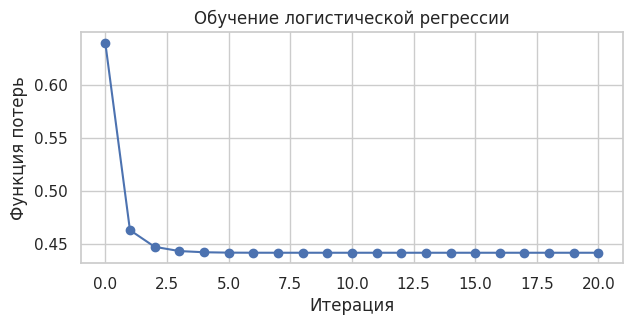

In [10]:
plt.figure(figsize=(7, 3))
plt.plot(lr_model.summary.objectiveHistory, marker="o")
plt.xlabel("Итерация")
plt.ylabel("Функция потерь")
plt.title("Обучение логистической регрессии")
save("lr_objective")
plt.show()

<a id="ch8"></a>
## 8. Качество на тесте

**Путь:** считаем площади под кривыми на обучении и тесте → сравниваем, нет ли переобучения → смотрим матрицу ошибок при стандартном пороге 0,5.

In [11]:
auc_pr = BinaryClassificationEvaluator(labelCol="severe", metricName="areaUnderPR")

train_predictions = model.transform(train).cache()  # понадобятся ещё для выбора порога
predictions = model.transform(test).cache()

pd.DataFrame({
    "обучение": [auc_roc.evaluate(train_predictions), auc_pr.evaluate(train_predictions)],
    "тест": [auc_roc.evaluate(predictions), auc_pr.evaluate(predictions)],
}, index=["AUC-ROC", "AUC-PR"]).round(3)

,обучение,тест
AUC-ROC,0.857,0.838
AUC-PR,0.769,0.721


Для сравнения: у случайного угадывания `AUC-ROC` = 0,5, а `AUC-PR` равна доле тяжёлых — около 0,34. Модель заметно лучше.

На тесте метрики немного ниже, чем на обучении: тест — это будущие годы, условия там чуть другие. Переобучения нет.

Матрица ошибок и метрики при пороге 0,5:

In [12]:
def report(predictions):
    # ключ — пара (факт, прогноз), значение — число записей
    counts = {(r["severe"], int(r["prediction"])): r["count"]
              for r in predictions.groupBy("severe", "prediction").count().collect()}
    tp, fp = counts.get((1, 1), 0), counts.get((0, 1), 0)
    fn, tn = counts.get((1, 0), 0), counts.get((0, 0), 0)
    precision = tp / (tp + fp)
    recall = tp / (tp + fn)
    print(f"TP = {tp:,}  FP = {fp:,}\nFN = {fn:,}  TN = {tn:,}")
    print(f"precision = {precision:.3f}, recall = {recall:.3f}, "
          f"F1 = {2 * precision * recall / (precision + recall):.3f}, accuracy = {(tp + tn) / (tp + fp + fn + tn):.3f}")


report(predictions)

TP = 141,445  FP = 61,189
FN = 80,177  TN = 362,843
precision = 0.698, recall = 0.638, F1 = 0.667, accuracy = 0.781


При пороге 0,5 модель находит около двух третей тяжёлых ДТП, и примерно 70 % её срабатываний верны.

<a id="ch9"></a>
## 9. ROC- и PR-кривые

**Путь:** округляем вероятность тяжёлого ДТП до сотых и считаем в Spark, сколько тяжёлых и лёгких ДТП получило каждую вероятность. По этой маленькой таблице кривые строятся в pandas накопленными суммами: порог идёт сверху вниз, и всё, что выше порога, считается тяжёлым.

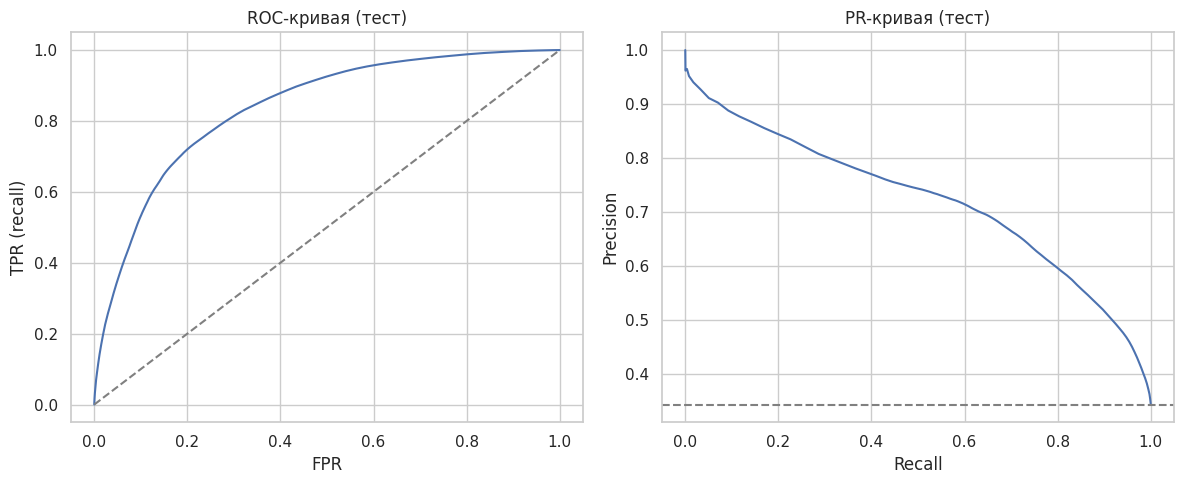

In [13]:
def curve_points(predictions):
    table = (
        predictions
        .select(F.round(vector_to_array("probability")[1], 2).alias("threshold"), "severe")
        .groupBy("threshold")
        .agg(F.sum("severe").alias("pos"), F.count("*").alias("total"))
        .toPandas()
        .sort_values("threshold", ascending=False)
    )
    tp = table["pos"].cumsum()
    fp = (table["total"] - table["pos"]).cumsum()
    table["tpr"] = tp / tp.iloc[-1]
    table["fpr"] = fp / fp.iloc[-1]
    table["precision"] = tp / (tp + fp)
    table["f1"] = 2 * table["precision"] * table["tpr"] / (table["precision"] + table["tpr"])
    return table


test_curve = curve_points(predictions)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].plot(test_curve["fpr"], test_curve["tpr"])
axes[0].plot([0, 1], [0, 1], color="gray", linestyle="--")
axes[0].set(xlabel="FPR", ylabel="TPR (recall)", title="ROC-кривая (тест)")
axes[1].plot(test_curve["tpr"], test_curve["precision"])
axes[1].axhline(test.agg(F.avg("severe")).first()[0], color="gray", linestyle="--")
axes[1].set(xlabel="Recall", ylabel="Precision", title="PR-кривая (тест)")
plt.tight_layout()
save("lr_roc_pr")
plt.show()

ROC-кривая идёт заметно выше диагонали, PR-кривая — выше уровня случайной модели на всём диапазоне полноты.

<a id="ch10"></a>
## 10. Порог решения

**Путь:** порог 0,5 не обязан быть лучшим. Выбираем порог с максимальной F1-мерой **на обучающей выборке** (тест для выбора трогать нельзя) → применяем к тесту.

In [14]:
train_curve = curve_points(train_predictions)
best_threshold = float(train_curve.loc[train_curve["f1"].idxmax(), "threshold"])
print(f"Порог с лучшей F1 на обучении: {best_threshold}")

lr_model.setThreshold(best_threshold)
predictions = model.transform(test)
report(predictions)

Порог с лучшей F1 на обучении: 0.33


TP = 168,405  FP = 101,744
FN = 53,217  TN = 322,288
precision = 0.623, recall = 0.760, F1 = 0.685, accuracy = 0.760


Более низкий порог поднимает полноту примерно до трёх четвертей ценой точности. Для диспетчера это разумный обмен: пропустить тяжёлое ДТП хуже, чем лишний раз проверить лёгкое.

<a id="ch11"></a>
## 11. Интерпретация коэффициентов

**Путь:** берём имена элементов вектора `features` из его метаданных → сопоставляем с коэффициентами → смотрим, что сильнее всего повышает и понижает шанс тяжёлого ДТП. Положительный коэффициент повышает шанс, отрицательный — понижает.

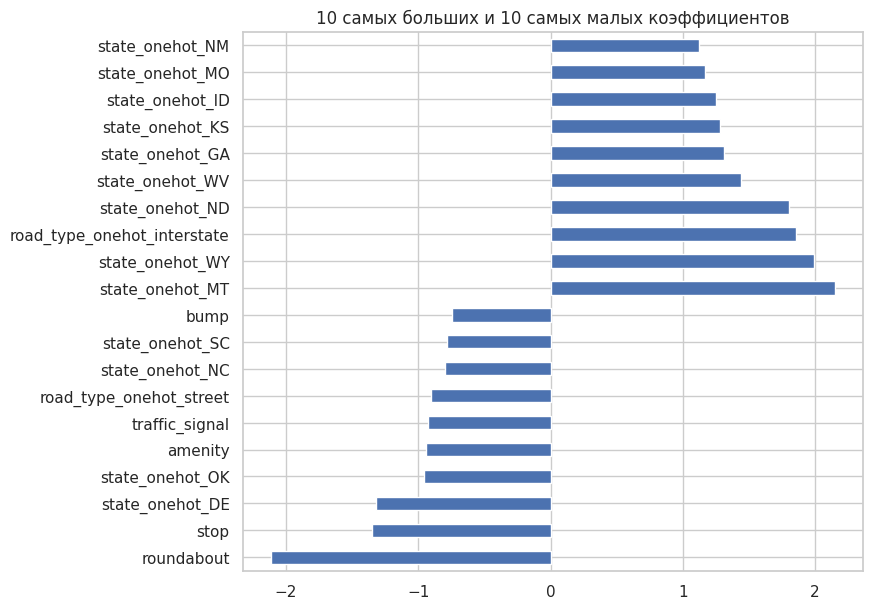

In [15]:
attributes = predictions.schema["features"].metadata["ml_attr"]["attrs"]
names = {a["idx"]: a["name"] for group in attributes.values() for a in group}
names = [names[i] for i in range(len(names))]
names = [numeric[int(n.rsplit("_", 1)[1])] if n.startswith("numeric_scaled_") else n for n in names]

coefficients = pd.Series(lr_model.coefficients.toArray(), index=names)
top = pd.concat([coefficients.nsmallest(10), coefficients.nlargest(10)])

top.plot.barh(figsize=(8, 7), title="10 самых больших и 10 самых малых коэффициентов")
save("lr_coefficients")
plt.show()

Шанс тяжёлого ДТП сильнее всего повышают межштатная магистраль и малонаселённые штаты с высокими скоростями на трассах (Монтана, Вайоминг, Северная Дакота). Понижают — кольцо, знак «стоп», светофор и обычная улица, где скорости низкие. Это совпадает с разведочным анализом.

<a id="ch12"></a>
## 12. Сохранение модели

**Путь:** сохраняем весь конвейер вместе с выбранным порогом в `HDFS` → загружаем обратно → проверяем, что на записях из `streaming-data.csv` он даёт те же ответы.

In [16]:
model_path = f"hdfs:///user/{user}/models/severity-logreg"
model.write().overwrite().save(model_path)

!hdfs dfs -ls {model_path}/stages

Found 6 items
drwxr-xr-x   - hadoop supergroup          0 2026-10-20 05:36 hdfs:///user/hadoop/models/severity-logreg/stages/0_StringIndexer_5fa1738d2de2
drwxr-xr-x   - hadoop supergroup          0 2026-10-20 05:36 hdfs:///user/hadoop/models/severity-logreg/stages/1_OneHotEncoder_f2cac7094da1
drwxr-xr-x   - hadoop supergroup          0 2026-10-20 05:36 hdfs:///user/hadoop/models/severity-logreg/stages/2_VectorAssembler_01232b0b7f24
drwxr-xr-x   - hadoop supergroup          0 2026-10-20 05:36 hdfs:///user/hadoop/models/severity-logreg/stages/3_StandardScaler_0b2ec10e3bc8
drwxr-xr-x   - hadoop supergroup          0 2026-10-20 05:36 hdfs:///user/hadoop/models/severity-logreg/stages/4_VectorAssembler_d6ba9f2752cc
drwxr-xr-x   - hadoop supergroup          0 2026-10-20 05:36 hdfs:///user/hadoop/models/severity-logreg/stages/5_LogisticRegression_bc8908de2703


In [17]:
loaded = PipelineModel.load(model_path)

original = model.transform(stream).select("id", "prediction").orderBy("id").collect()
restored = loaded.transform(stream).select("id", "prediction").orderBy("id").collect()
print(f"Ответы совпадают: {original == restored}, порог в загруженной модели: {loaded.stages[-1].getThreshold()}")

Ответы совпадают: True, порог в загруженной модели: 0.33


<a id="ch13"></a>
## 13. Выводы

* Задача — по условиям ДТП предсказать, будет ли оно тяжёлым (тяжесть 3–4). Взят только `Source2`, где разметка тяжести стабильна: 3,3 млн записей, треть тяжёлых.
* Разделение по времени: обучение — 2016–2020 (2,65 млн), тест — 2021–2022 (0,65 млн). Признаки — только известные в момент сообщения; длительность и протяжённость исключены как утечка.
* Конвейер `SparkML`: индексирование и one-hot кодирование категорий и календаря, стандартизация погоды, логистическая регрессия — всего 126 признаков. Кросс-валидация выбрала L2-регуляризацию с `regParam` = 0,01.
* Качество на тесте: `AUC-ROC` 0,838, `AUC-PR` 0,721 при уровне случайной модели 0,34. С порогом 0,33, выбранным на обучении, модель находит 76 % тяжёлых ДТП при точности 62 %.
* Главные факторы — тип дороги и штат, затем объекты рядом: кольцо, «стоп» и светофор снижают шанс тяжёлого ДТП.
* Конвейер с порогом сохранён в `HDFS` (`models/severity-logreg`), около тысячи тестовых записей — в `streaming-data.csv` для лабораторной № 3.

In [18]:
spark.stop()